In [53]:
%load_ext autoreload
%autoreload 2

from fsl_mrs.utils.synthetic import synthetic_from_dynamic as syn
from fsl_mrs.utils import mrs_io
from fsl_mrs.utils import plotting as splot

import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
basis = mrs_io.read_basis('basis')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the two direction files 

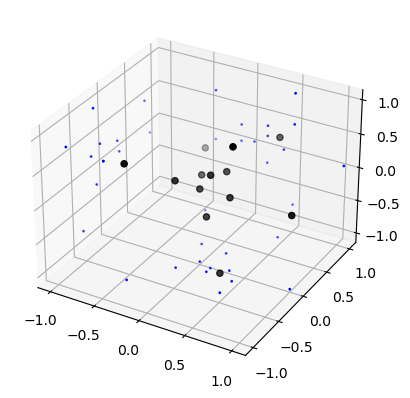

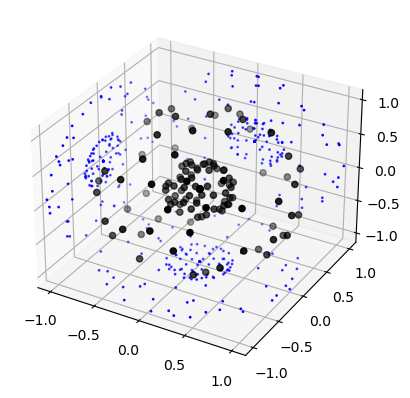

In [54]:
def load_file(file_path, max_bvalue=3, plot=True):
    bvecs = []
    bvptrn = re.compile(r'Vector\[\d+\] = \((.*)\)')
    with open(file_path) as bv:
        for line in bv.readlines():
            match = bvptrn.match(line)
            if match:
                bvecs.append([float(x) for x in match[1].split(',')])
    bvecs = np.asarray(bvecs)

    if plot:
        fig = plt.figure()
        ax = fig.add_subplot(projection='3d')
        ax.scatter(bvecs[:,0], bvecs[:,1], -1.1 + 0*bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], 1.1 + 0*bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(-1.1 + 0*bvecs[:,0], bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], bvecs[:,1], bvecs[:,2], c='k')
        ax.set_xlim([-1.1, 1.1])
        ax.set_ylim([-1.1, 1.1])
        ax.set_zlim([-1.1, 1.1])
        plt.show()

    return bvecs * max_bvalue

b_6_dir =load_file('b_1000_3000_6dir', max_bvalue=3, plot=True)
b_60_dir =load_file('b_1000_3000_60dir', max_bvalue=3, plot=True)



### Generate ball and sticks parameters

's0', 'd', 'th1', 'ph1', 'f1', 'th2', 'ph2', 'f2'  
s + f1 + f2 = 1

In [55]:
def get_metabolite_bs_params(metab, adc_mean, adc_sd):
    rng = np.random.default_rng()
    adc = 0
    while adc <= 0:
        adc = adc_mean + rng.standard_normal(1) * adc_sd
    if metab == 'NAA':
        # NAA is equally in two crossing fibres
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.5,
            f'conc_{metab}_th2': np.pi,
            f'conc_{metab}_ph2': np.pi,
            f'conc_{metab}_f2': 0.5}

    elif metab == 'Ins':
        # Ins is in astrocytes, mostly non-directional
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.1,
            f'conc_{metab}_th2': 0,
            f'conc_{metab}_ph2': 0,
            f'conc_{metab}_f2': 0.00}
    elif metab == 'Cr':
        # Mix of above
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.25,
            f'conc_{metab}_th2': np.pi,
            f'conc_{metab}_ph2': np.pi,
            f'conc_{metab}_f2': 0.25}

    else:
        raise ValueError(f'{metab} Metabolite not recognised')

print(get_metabolite_bs_params('NAA', 0.22, 0.02))

{'conc_NAA_d': 0.19533518896384694, 'conc_NAA_th1': 3.141592653589793, 'conc_NAA_ph1': 0, 'conc_NAA_f1': 0.5, 'conc_NAA_th2': 3.141592653589793, 'conc_NAA_ph2': 3.141592653589793, 'conc_NAA_f2': 0.5}


### Generate data for each set of directions and the precomputed random tensors

Noise variance for the 6 direction data should be 10 times less than the 60 direction, to match total experiment time.

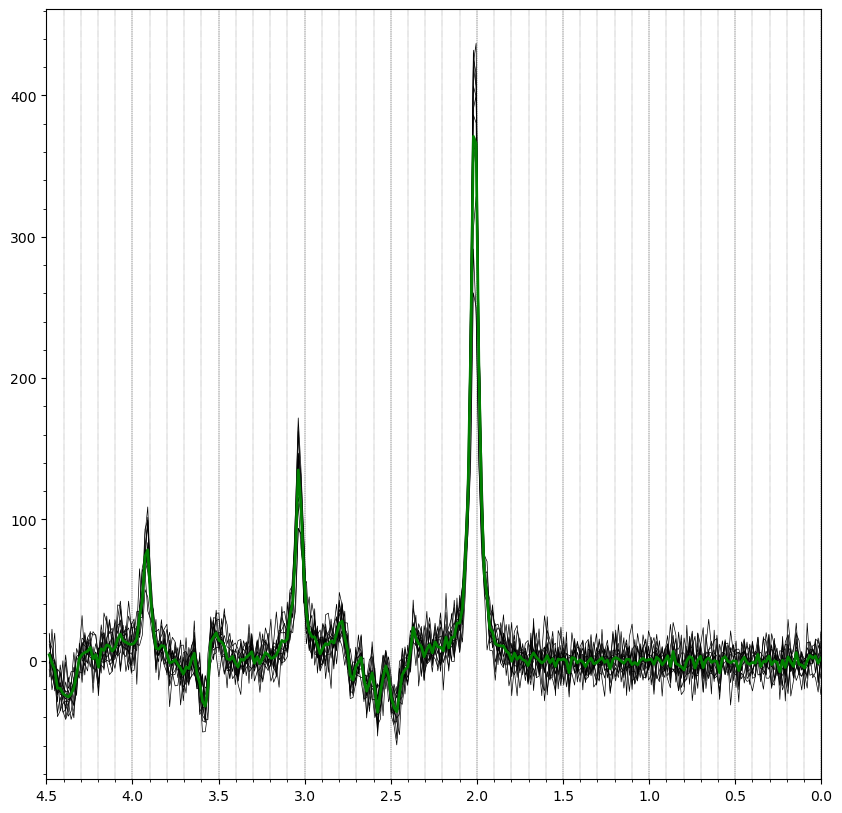

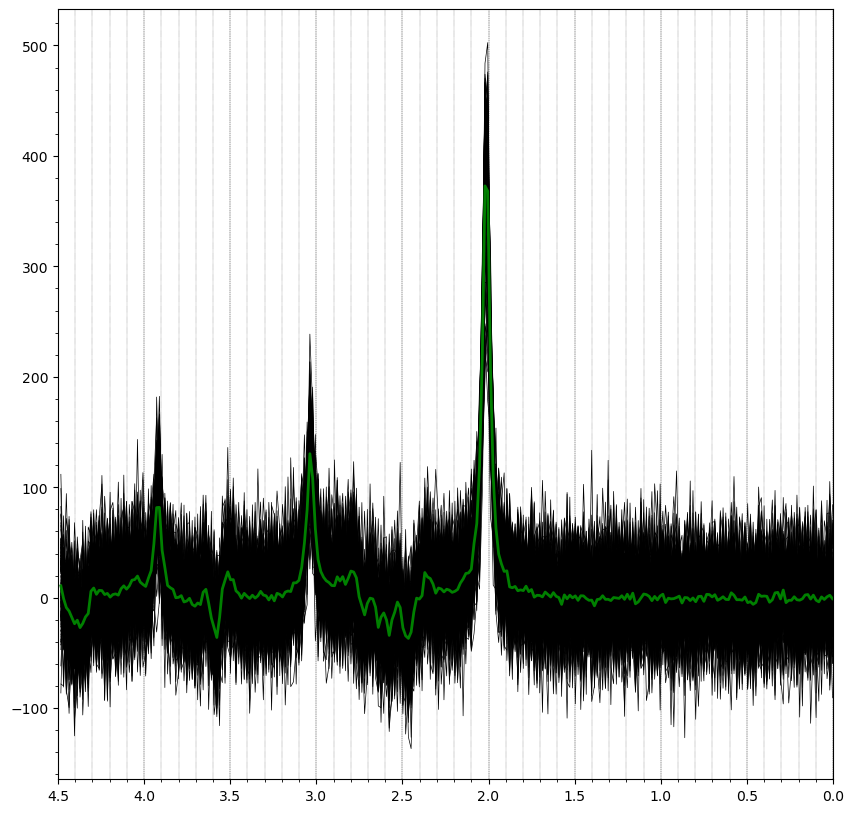

In [66]:
ignore_metabs = ['Tau', 'Scyllo', 'PE', 'PCr', 'PCh', 'NAAG', 'Lac', 'Gln', 'Glc', 'GSH', 'GPC', 'Asp', 'Asc', 'Ala', 'GABA', 'Glu']

def generate_dataset(directions, noisevar, defined_values):

    mrs_list, vm_obj, ground_truth = syn.synthetic_spectra_from_model(
        'model_ball2sticks.py',
        directions,
        'basis',
        ignore=ignore_metabs,
        metab_groups=None,
        ind_scaling=None,
        concentrations=None,
        baseline_order=0,
        baseline_ppm=None,
        defined_vals=defined_vals,
        param_noise=None,
        param_rel_noise=None,
        noisecovariance=[[noisevar]],
        bandwidth=2000,
        points=1024
    )

    _ = splot.plot_spectra(mrs_list)
    truth_df = pd.Series(ground_truth, index=vm_obj.free_names)
    return mrs_list, truth_df

from fsl_mrs.utils.synthetic.synthetic_from_basis import standardConcentrations
std_concs = standardConcentrations(basis.names)

defined_vals = {
    'gamma_0': 16,
    'sigma_0': 0
}
for name, conc in zip(basis.get_formatted_names(ignore_metabs), std_concs):
    defined_vals[f'conc_{name}_c_S0'] = conc
    defined_vals.update(get_metabolite_bs_params(name, 0.22, 0.02))

mrs_list_6, truth_df_6 = generate_dataset(b_6_dir, 100, defined_vals)
mrs_list_60, truth_df_60 = generate_dataset(b_60_dir, 1000, defined_vals)

In [67]:
from fsl_mrs.dynamic import dynMRS

fit_args = {'model': 'lorentzian',
            'ppmlim': (0.2, 4.2),
            'baseline_order': 0}

# Create the dynamic fitting object
dyn_6 = dynMRS(mrs_list_6, b_6_dir, config_file='model_ball2sticks.py', rescale=False, **fit_args)

# Initialise the fit.
init_6 = dyn_6.initialise(verbose=True, indiv_init='mean')

dyn_res_6 = dyn_6.fit(init=init_6, verbose=True, method='Newton')

Init done in 4.1456708908081055 seconds.
Start fitting
...completed in 9.758347988128662 seconds.
Collect results
...completed in 0.320526123046875 seconds.


In [68]:
# Create the dynamic fitting object
dyn_60 = dynMRS(mrs_list_60, b_60_dir, config_file='model_ball2sticks.py', rescale=False, **fit_args)

# Initialise the fit.
init_60 = dyn_60.initialise(verbose=True, indiv_init='mean')

dyn_res_60 = dyn_60.fit(init=init_60, verbose=True, method='Newton')

Init done in 34.60214304924011 seconds.
Start fitting
...completed in 102.52748799324036 seconds.
Collect results
...completed in 3.169572114944458 seconds.


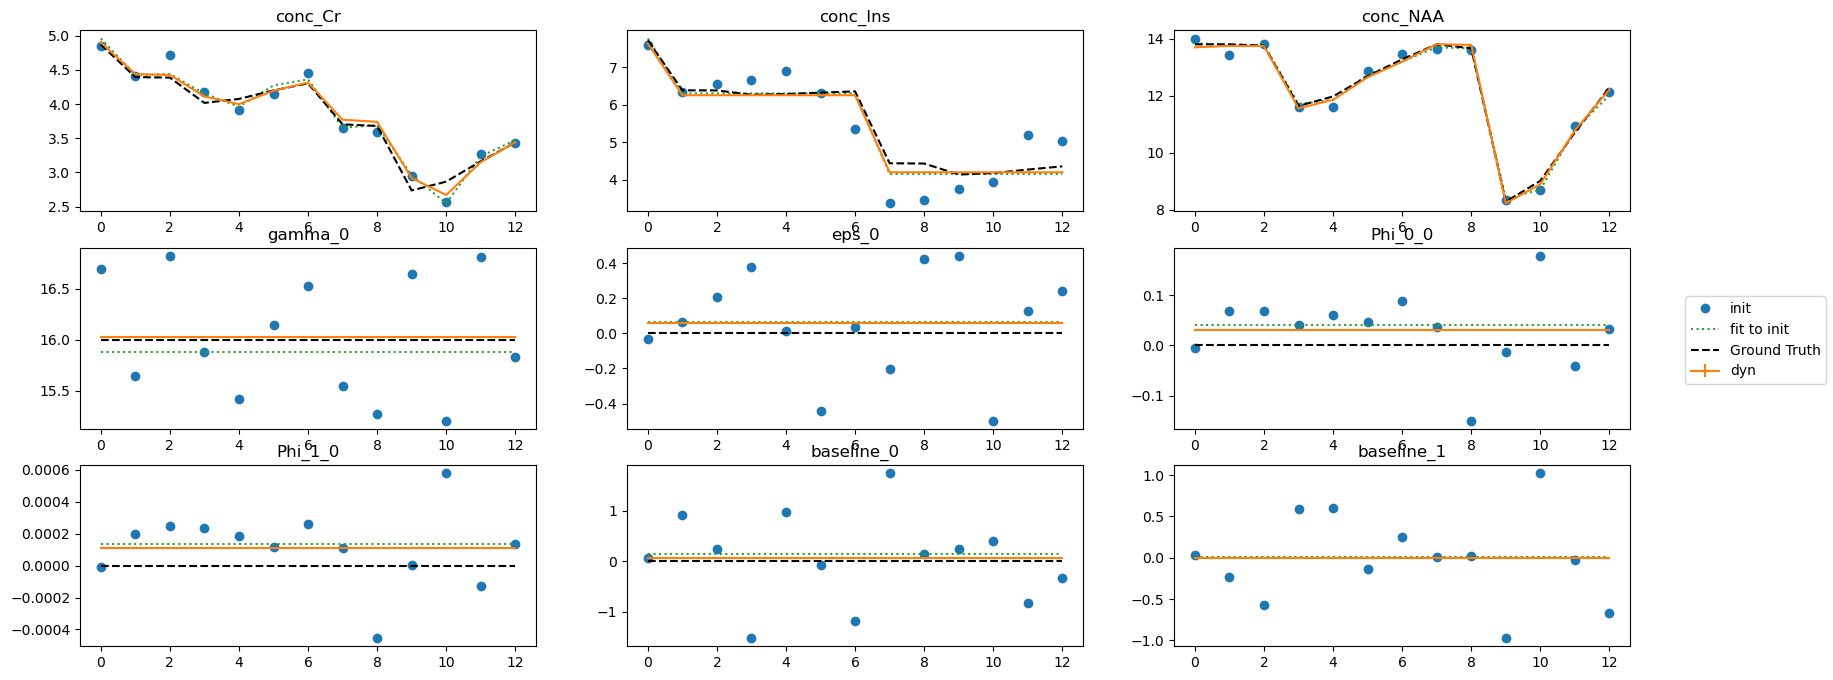

In [69]:
fig = dyn_res_6.plot_mapped(tvals=np.arange(b_6_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_6.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

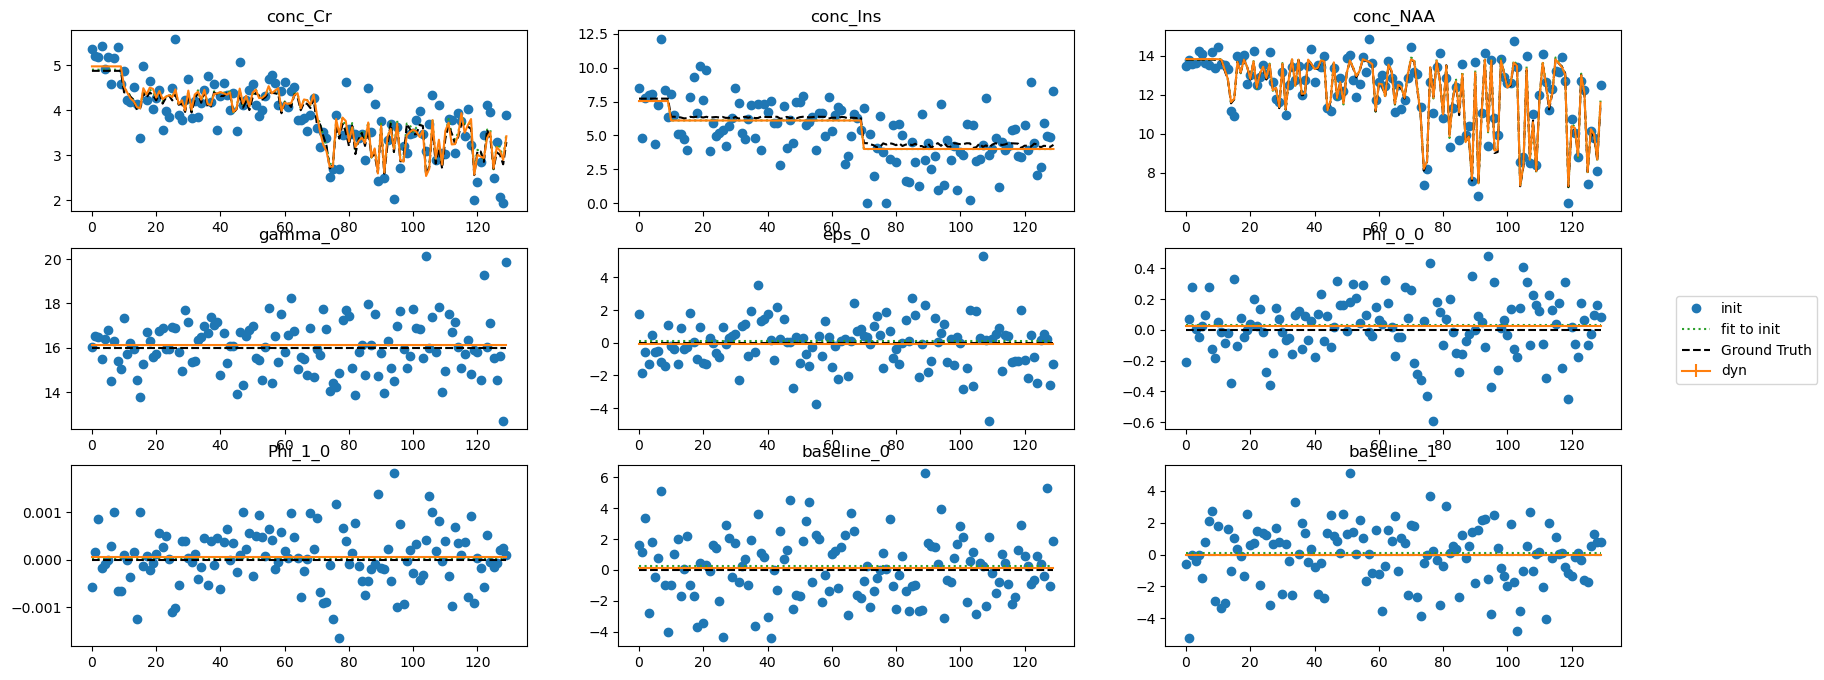

In [70]:
fig = dyn_res_60.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [72]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6.dataframe_free.T[0], dyn_res_60.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir'])
comp_df

,true,6_dir,60_dir
conc_Cr_s0,4.870000,4.901701,4.968830
conc_Cr_d,0.217332,0.241940,0.263063
conc_Cr_th1,3.141593,-0.357731,0.411920
conc_Cr_ph1,0.000000,0.720052,-1.263096
conc_Cr_f1,0.250000,0.277404,0.399518
conc_Cr_th2,3.141593,-0.384607,-0.604652
conc_Cr_ph2,3.141593,-1.381667,-1.373159
conc_Cr_f2,0.250000,0.304071,0.221794
conc_Ins_s0,7.720000,7.636104,7.541788
conc_Ins_d,0.213241,0.199602,0.211167


In [84]:
100*comp_df[['6_dir','60_dir']].subtract(comp_df.true,axis=0).divide(comp_df.true, axis=0)

,6_dir,60_dir
conc_Cr_s0,0.650939,2.029364
conc_Cr_d,11.322588,21.041594
conc_Cr_th1,-111.386945,-86.888182
conc_Cr_ph1,inf,-inf
conc_Cr_f1,10.961529,59.807143
conc_Cr_th2,-112.242411,-119.246656
conc_Cr_ph2,-143.979818,-143.709006
conc_Cr_f2,21.628485,-11.282402
conc_Ins_s0,-1.086729,-2.308444
conc_Ins_d,-6.396096,-0.972794


## Analyse results

### Perfect initialisation

Start fitting
...completed in 127.68133926391602 seconds.
Collect results
...completed in 2.8998069763183594 seconds.


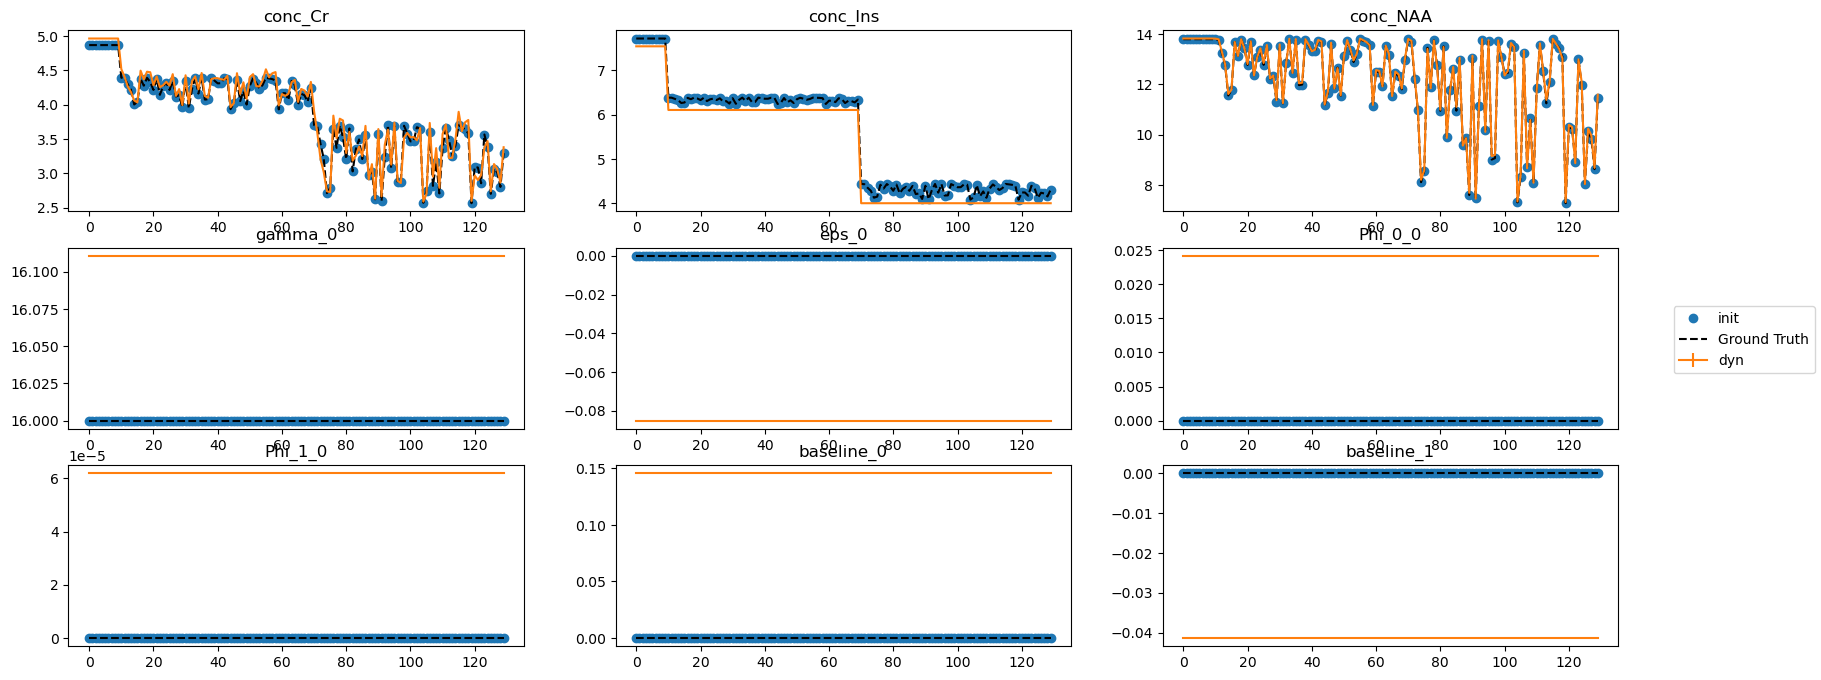

In [85]:
dyn_res_perfect = dyn_60.fit(x0=truth_df_60.drop('sigma_0').to_numpy(), verbose=True, method='Newton')
fig = dyn_res_perfect.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=False, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [86]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6.dataframe_free.T[0], dyn_res_60.dataframe_free.T[0], dyn_res_perfect.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir', 'perfect'])
comp_df

,true,6_dir,60_dir,perfect
conc_Cr_s0,4.870000,4.901701,4.968830,4.965930
conc_Cr_d,0.217332,0.241940,0.263063,0.257566
conc_Cr_th1,3.141593,-0.357731,0.411920,3.356081
conc_Cr_ph1,0.000000,0.720052,-1.263096,-1.192015
conc_Cr_f1,0.250000,0.277404,0.399518,0.486889
conc_Cr_th2,3.141593,-0.384607,-0.604652,1.100005
conc_Cr_ph2,3.141593,-1.381667,-1.373159,1.672590
conc_Cr_f2,0.250000,0.304071,0.221794,0.121772
conc_Ins_s0,7.720000,7.636104,7.541788,7.543683
conc_Ins_d,0.213241,0.199602,0.211167,0.211354
